<a href="https://colab.research.google.com/github/heythisbenittababu/Assesment_supervised_Learning_Benitta_Babu/blob/main/Assesment_Supervisedlearning_Benitta_Babu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [120]:
import pandas as pd

1. Data understanding and exploratory analysis.

In [121]:
filepath='/content/drive/MyDrive/DSA/Datasets/bank_marketing_assessment_dataset.csv'
df=pd.read_csv(filepath)
df.head(10)

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no
5,40,technician,single,secondary,846.0,yes,yes,cellular,nov,5,0,9,24227,no
6,18,admin,married,secondary,-325.0,no,no,telephone,jul,4,0,3,27178,no
7,49,retired,single,tertiary,479.0,no,no,unknown,aug,4,0,4,41245,no
8,44,admin,married,secondary,-1013.0,no,no,unknown,jun,7,0,2,12000,no
9,40,technician,married,secondary,-202.0,no,no,cellular,jul,5,0,3,22036,no


In [122]:
df.shape

(600, 14)

In [123]:
df.columns

Index(['customer_age', 'job', 'marital_status', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact_type', 'contact_month',
       'campaign_contacts', 'previous_contacts', 'engagement_score',
       'annual_income_estimate', 'subscribed'],
      dtype='object')

In [124]:
df.dtypes

,0
customer_age,int64
job,object
marital_status,object
education,object
account_balance,float64
housing_loan,object
personal_loan,object
contact_type,object
contact_month,object
campaign_contacts,int64


In [125]:
df.isna().sum()

,0
customer_age,0
job,0
marital_status,0
education,15
account_balance,12
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [126]:
df.duplicated().sum()

np.int64(0)

There is zero duplicated records in the dataset


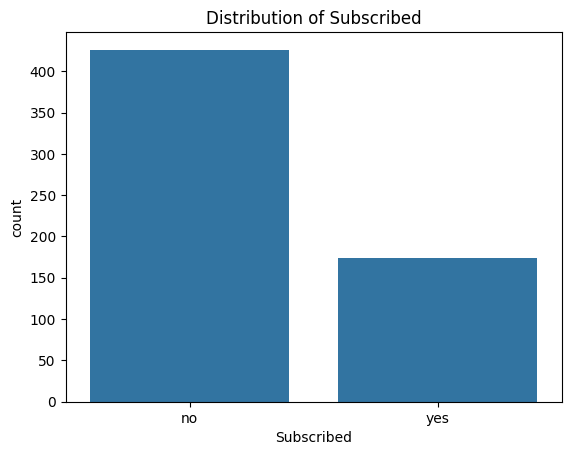

In [127]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(x='subscribed', data=df)
plt.title('Distribution of Subscribed')
plt.xlabel('Subscribed')
plt.show()

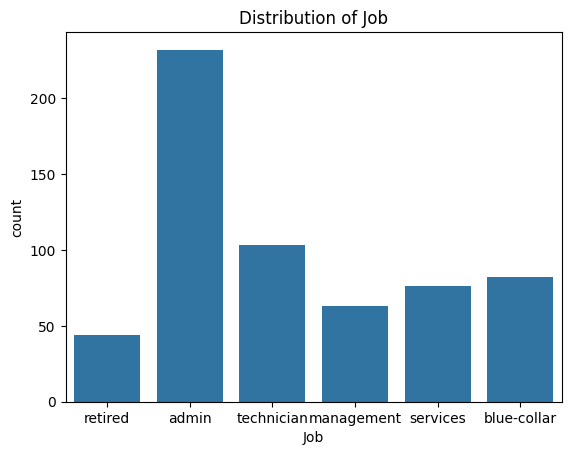

In [128]:
sns.countplot(x='job', data=df)
plt.title('Distribution of Job')
plt.xlabel('Job')
plt.show()

2. Data Preparation and feature engineering

In [129]:
mode_val = df['education'].mode()[0]
df['education'] = df['education'].fillna(mode_val)
df['education'].isna().sum()

median = df['account_balance'].median()
df['account_balance'] = df['account_balance'].fillna(median)
df['account_balance'].isna().sum()

np.int64(0)

In [130]:
df.isna().sum()

,0
customer_age,0
job,0
marital_status,0
education,0
account_balance,0
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [131]:
categorical_cols = df.select_dtypes(include=['object']).columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: Index(['job', 'marital_status', 'education', 'housing_loan', 'personal_loan',
       'contact_type', 'contact_month', 'subscribed'],
      dtype='object')
Numerical columns: Index(['customer_age', 'account_balance', 'campaign_contacts',
       'previous_contacts', 'engagement_score', 'annual_income_estimate'],
      dtype='object')


In [132]:
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
df_encoded.head()

,customer_age,account_balance,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,job_blue-collar,job_management,job_retired,job_services,...,housing_loan_yes,personal_loan_yes,contact_type_telephone,contact_type_unknown,contact_month_jul,contact_month_jun,contact_month_may,contact_month_nov,contact_month_oct,subscribed_yes
0,69,5467.0,4,0,8,23029,False,False,True,False,...,False,False,False,True,False,False,False,True,False,False
1,21,606.0,8,0,1,12000,False,False,False,False,...,False,False,True,False,False,False,True,False,False,False
2,27,-314.0,12,0,10,43597,False,False,False,False,...,True,False,False,False,False,False,False,True,False,False
3,53,1503.0,6,0,10,24602,False,True,False,False,...,True,True,False,False,False,False,False,True,False,False
4,51,3037.0,5,0,2,27127,False,True,False,False,...,False,False,False,True,False,True,False,False,False,False


In [133]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_encoded[numerical_cols] = scaler.fit_transform(df_encoded[numerical_cols])
df_encoded.head()

,customer_age,account_balance,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,job_blue-collar,job_management,job_retired,job_services,...,housing_loan_yes,personal_loan_yes,contact_type_telephone,contact_type_unknown,contact_month_jul,contact_month_jun,contact_month_may,contact_month_nov,contact_month_oct,subscribed_yes
0,2.002762,1.679037,-0.776038,-0.641757,1.208497,-0.508784,False,False,True,False,...,False,False,False,True,False,False,False,True,False,False
1,-1.119270,-0.397295,1.205336,-0.641757,-1.175574,-1.148158,False,False,False,False,...,False,False,True,False,False,False,True,False,False,False
2,-0.729016,-0.790265,3.186711,-0.641757,1.889661,0.683585,False,False,False,False,...,True,False,False,False,False,False,False,True,False,False
3,0.962085,-0.014150,0.214649,-0.641757,1.889661,-0.417594,False,True,False,False,...,True,True,False,False,False,False,False,True,False,False
4,0.832000,0.641085,-0.280695,-0.641757,-0.834993,-0.271214,False,True,False,False,...,False,False,False,True,False,True,False,False,False,False


In [134]:
# 1. Separate features and target from the preprocessed encoded DataFrame
X = df_encoded.drop(columns=['subscribed_yes'])
y = df_encoded['subscribed_yes']

# 2. Perform stratified train-test split (80:20)
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



Logistic regression model successfully fitted!
Predictions: [False False False False False False False  True False False  True False
 False  True  True False False False False False False False False  True
 False False False False False  True False False False False False False
 False False False False False  True  True False False False  True  True
 False  True False False False False  True False  True False False False
 False False False False False  True False  True False False False False
 False False False False  True False False False False False False False
 False False False False False  True False  True False False False False
  True False False False False False  True False False  True False False
 False False  True  True  True False  True False False False False  True]


3. Model building

In [143]:
# 3. Build and fit the Logistic Regression model
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000)
lr.fit(x_train, y_train)

# 4. Predict and evaluate
y_pred_lr = model.predict(x_test)
print('Logistic regression model successfully fitted!')
print('Predictions:', y_pred)

Logistic regression model successfully fitted!
Predictions: [False False False False False False False  True False False  True False
 False  True  True False False False False False False False False  True
 False False False False False  True False False False False False False
 False False False False False  True  True False False False  True  True
 False  True False False False False  True False  True False False False
 False False False False False  True False  True False False False False
 False False False False  True False False False False False False False
 False False False False False  True False  True False False False False
  True False False False False False  True False False  True False False
 False False  True  True  True False  True False False False False  True]


In [135]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
print('Confusion Matrix:', confusion_matrix(y_test, y_pred))
print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
print('F1 score:', f1_score(y_test, y_pred))

Confusion Matrix: [[78  4]
 [16 22]]
Accuracy: 0.8333333333333334
Precision: 0.8461538461538461
Recall: 0.5789473684210527
F1 score: 0.6875


In [136]:
#Build a Decision Tree or Random Forest classification model.
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(random_state=42)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
print('Random Forest model successfully fitted!')
print('Predictions:', y_pred)


Random Forest model successfully fitted!
Predictions: [False False False False False False False  True False False  True False
 False  True  True False False False False False False False False  True
 False False False False False  True False False False False False False
 False False False False False  True  True False False  True  True  True
 False  True False False False False  True False  True False False False
 False False False False False  True False  True False False False False
 False False False False  True False False False False False False False
 False False False False False  True False  True False False False False
  True False False False False False  True False False  True False False
 False False  True  True  True False  True False False False False  True]


In [137]:
print('Confusion Matrix:', confusion_matrix(y_test, y_pred))
print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
print('F1 score:', f1_score(y_test, y_pred))

Confusion Matrix: [[78  4]
 [15 23]]
Accuracy: 0.8416666666666667
Precision: 0.8518518518518519
Recall: 0.6052631578947368
F1 score: 0.7076923076923077


In [138]:
#•	Use a reproducible preprocessing/model pipeline where appropriate.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(random_state=42))
])
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
print('Pipeline model successfully fitted!')
print('Predictions:', y_pred)

Pipeline model successfully fitted!
Predictions: [False False False False False False False  True False False  True False
 False  True  True False False False False False False False False  True
 False False False False False  True False False False False False False
 False False False False False  True  True False False False  True  True
 False  True False False False False  True False  True False False False
 False False False False False  True False  True False False False False
 False False False False  True False False False False False False False
 False False False False False  True False  True False False False False
  True False False False False False  True False False  True False False
 False False  True  True  True False  True False False False False  True]


In [140]:
print('Confusion Matrix:', confusion_matrix(y_test, y_pred))
print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
print('F1 score:', f1_score(y_test, y_pred))

Confusion Matrix: [[78  4]
 [16 22]]
Accuracy: 0.8333333333333334
Precision: 0.8461538461538461
Recall: 0.5789473684210527
F1 score: 0.6875


4. Model evaluation and comparison

In [142]:
# 1. Evaluate Logistic Regression
y_pred_lr = lr.predict(x_test)
print("=== Logistic Regression Performance ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr):.4f} (Crucial for finding subscribers)")
print(f"F1-Score:  {f1_score(y_test, y_pred_lr):.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))

# 2. Evaluate Random Forest
print("\n=== Random Forest Performance ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f} (Crucial for finding subscribers)")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

=== Logistic Regression Performance ===
Accuracy:  0.8083
Precision: 0.7778
Recall:    0.5526 (Crucial for finding subscribers)
F1-Score:  0.6462
Confusion Matrix:
 [[76  6]
 [17 21]]

=== Random Forest Performance ===
Accuracy:  0.8333
Precision: 0.8462
Recall:    0.5789 (Crucial for finding subscribers)
F1-Score:  0.6875
Confusion Matrix:
 [[78  4]
 [16 22]]


Random forest model achieve highest recall score = 60.53% so i recomment the random forest model for the buisness problem
Logic Regresssion Achieved recall score = 55.26%.
Random Forest Achieved accuracy score=83.33%
Logic Regression achieved accuracy score=80.83

The random forest classifier is the superior model . it dominates across every matric,providing a higher balance of performance (F1-score of 70.77% vs 64.62% for logistic Regression ) and higher in overall accuracy.it will maximize subscription while optimize the bank operational marketing efficiently.

5. Business interpretation and prediction

/tmp/ipykernel_6345/2028593119.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance_df.head(10), x='Importance', y='Feature', palette='Pastel2')


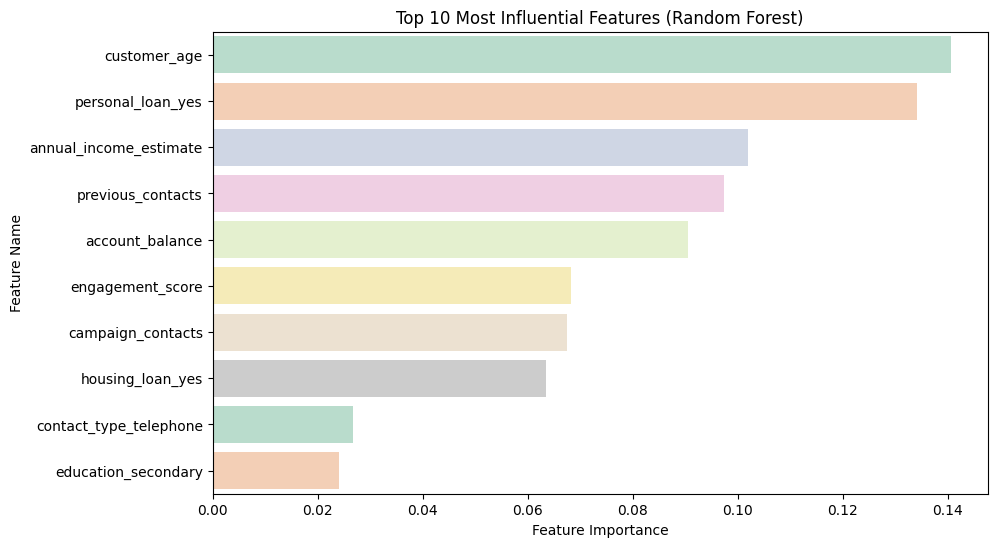

In [147]:
# Identify the most influential features using a suitable model interpretation method. Explain the limitations of the interpretation.
# Extract feature importances directly from the features (X) and the trained Random Forest model
feature_names = X.columns.tolist()
importances = model.feature_importances_

# Create a DataFrame for easy viewing
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

# Plot top 10 features
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df.head(10), x='Importance', y='Feature', palette='Pastel2')
plt.title('Top 10 Most Influential Features (Random Forest)')
plt.xlabel('Feature Importance')
plt.ylabel('Feature Name')
plt.show()

the customer age and the personal loan_yes is the top 2 feature that influence the most
i already displayed the top 10 features that influence.